# 15 — Skenario B: Informasi Penutupan Pasar Hari-t (analisis sensitivitas waktu)

**Latar belakang.** Pada protokol utama, semua indikator makro di-lag 1 hari kerja. Pemeriksaan lead–lag (notebook 03) menunjukkan bahwa harga Antam hari *t* sudah memuat sebagian besar informasi penutupan pasar AS hari *t−1*; korelasi indikator ber-lag-1 dengan return Antam *t+1* sangat kecil, sedangkan korelasi dengan penutupan pasar **hari t** jauh lebih besar. Artinya desain lag-1 **konservatif** (aman dari kebocoran) tetapi bisa membuang informasi yang sebenarnya sudah tersedia pada waktu peramalan.

**Skenario B ("origin malam hari").** Peramalan dibuat setelah pasar AS hari *t* tutup (malam hari *t*) dan sebelum harga Antam hari *t+1* diumumkan. Fitur pasar harian (DXY, S&P 500, USD/IDR, IHSG, US10Y) memakai nilai penutupan hari *t*; FFR (bulanan) dan BI-Rate **tetap lag-1**.

**Peringatan.** (i) Skenario B adalah **analisis sensitivitas**, bukan pengganti protokol utama. (ii) Validitasnya bergantung pada asumsi waktu publikasi harga Antam (dataset tidak mencatat jam publikasi): asumsi itu harus diverifikasi sebelum skenario B dijadikan klaim. (iii) Tidak ada pemilihan model atau hiperparameter baru: DL memakai (lr, wd) yang sama dengan run utama multivariat.

Hasil per run: `results/skenario_b/runs/`. Perkiraan waktu FULL (CPU 2 thread): 10 ML ≈ 5 menit; 2 DL × 5 horizon ≈ 15–30 menit.

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif selama training berjam-jam.
# Default 2 thread. Ubah lewat env TA_THREADS. Harus di kernel BARU (sebelum numpy/tensorflow aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
try:
    tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print('[PERHATIAN] TensorFlow sudah aktif di kernel ini, batas thread tidak berlaku. Restart kernel.')

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK,
                        SEQ_LEN, EPOCHS, PATIENCE, BASE_LR, BASE_WD, DL_BATCH, DL_UNITS)
from src import analysis as A, plots as P, stats as S, runners as R
from src.pipeline import SEED, load_mossa, free_memory
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
MODEL_DIR = os.path.join(RES, 'models')
for _d in (RES, RUNS, FIGS, MODEL_DIR):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

import json
from src.config import SCEN_B_DIRNAME, SCEN_B_DL
from src.pipeline import make_exo_scenario_b, EXO_B_SAMEDAY
wakil = A.load_wakil(RES)
reps = [wakil['dpformer'], wakil['dl']]
SB_RUNS = os.path.join(RES, SCEN_B_DIRNAME, 'runs')
SUB_B = f'{SCEN_B_DIRNAME}/runs'
LB = 'skenario_b'
os.makedirs(SB_RUNS, exist_ok=True)
mossa_all = load_mossa(os.path.join(RES, 'mossa_dpformer.json'))

exo_b = make_exo_scenario_b(exo)
# verifikasi konstruksi: baris t memuat nilai pasar hari t (= baris t+1 pada exo yang sudah lag-1)
assert np.allclose(exo_b[EXO_B_SAMEDAY].iloc[:-1].values, exo[EXO_B_SAMEDAY].iloc[1:].values)
assert exo_b[EXO_B_SAMEDAY].iloc[-1].isna().all()
print('Kolom yang memakai penutupan hari-t:', EXO_B_SAMEDAY)
print('Kolom tetap lag-1:', [c for c in exo.columns if c not in EXO_B_SAMEDAY])

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44
Kolom yang memakai penutupan hari-t: ['dxy_ret', 'sp500_ret', 'usd_idr_ret', 'ihsg_ret', 'us10yr_diff']
Kolom tetap lag-1: ['ffr_diff', 'bi_rate_diff']


In [2]:
def lr_wd_multi(model):
    if model == 'dpformer':
        lr, wd, _ = mossa_all['multivariat']
        return lr, wd
    return BASE_LR, BASE_WD


def run_b_ml(lb, m, h):
    return R.run_ml(p, exo_b, lb, m, h, rev=ML_REV, data_hash=DATA_HASH)


def run_b_dl(lb, m, h):
    lr, wd = lr_wd_multi(m)
    return R.run_dl(p, exo_b, lb, m, h, lr=lr, wd=wd, data_hash=DATA_HASH)


c1 = R.run_grid([(LB, m, h) for m in ML_MODELS for h in HORIZONS], run_b_ml, SB_RUNS, rev=ML_REV, data_hash=DATA_HASH)
assert c1['gagal'] == 0, c1['daftar_gagal']
if SCEN_B_DL:
    c2 = R.run_grid([(LB, m, h) for m in reps for h in HORIZONS], run_b_dl, SB_RUNS, data_hash=DATA_HASH)
    assert c2['gagal'] == 0, c2['daftar_gagal']

RUN  skenario_b/lightgbm/h1 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[156]	valid_0's rmse: 0.00563125
OK MAE=12,689 (0.9s)
RUN  skenario_b/lightgbm/h5 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[87]	valid_0's rmse: 0.0129464
OK MAE=29,942 (0.4s)
RUN  skenario_b/lightgbm/h10 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[90]	valid_0's rmse: 0.0182829
OK MAE=42,438 (0.3s)
RUN  skenario_b/lightgbm/h20 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[18]	valid_0's rmse: 0.0245141
OK MAE=62,300 (0.2s)
RUN  skenario_b/lightgbm/h30 ... Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[7]	valid_0's rmse: 0.0282166
OK MAE=83,060 (0.2s)
RUN  skenario_b/xgboost/h1 ... OK MAE=12,730 (3.1s)
RUN  skenario_b/xgboost/h5 ... OK MAE=30,050

## Hasil terhadap Drift dan terhadap protokol utama

In [3]:
models_b = ML_MODELS + (reps if SCEN_B_DL else [])
t_b = A.dm_vs_drift_table(RES, p, [LB], models_b, HORIZONS, runs_sub=SUB_B)
t_m = A.dm_vs_drift_table(RES, p, SETUPS, models_b, HORIZONS)             # pembanding: hasil utama untuk model yang sama
allt = pd.concat([t_m, t_b], ignore_index=True)
allt.to_csv(os.path.join(RES, 'skenario_b_dm_vs_drift.csv'), index=False)

ring = []
for s in ['univariat', 'multivariat', LB]:
    t = allt[allt.setup == s]
    ring.append({'skenario': s, **{k: v for k, v in A.summarize_dm(t, q_cols=('q_bh_setup',)).items()}})
print(f'Uji DM terhadap Drift (HLN, ruang return), {len(models_b)} model x {len(HORIZONS)} horizon per skenario:')
display(pd.DataFrame(ring).set_index('skenario'))

print('Rasio MSE-return model/Drift (<1 = lebih baik dari Drift), skenario B:')
display(t_b.pivot(index='model', columns='horizon', values='rel_mse_ret').reindex(models_b).round(3))
print('p-value DM satu-sisi (HLN), skenario B:')
display(t_b.pivot(index='model', columns='horizon', values='p_one_hln').reindex(models_b).round(4))

Uji DM terhadap Drift (HLN, ruang return), 12 model x 5 horizon per skenario:


,n_uji,n_p<0.05,n_p<0.10,n_lebih_baik_dari_drift (rel_mse<1),n_q_bh_setup<0.05
skenario,,,,,
univariat,60,9,15,36,0
multivariat,60,4,13,36,0
skenario_b,60,13,18,44,7


Rasio MSE-return model/Drift (<1 = lebih baik dari Drift), skenario B:


horizon,1,5,10,20,30
model,,,,,
lightgbm,0.912,0.990,0.995,0.980,0.998
xgboost,0.924,0.991,0.991,0.993,0.990
rf,0.930,0.991,0.976,0.948,0.975
catboost,0.926,0.981,0.982,0.998,0.994
gbm,0.958,1.043,1.019,1.044,1.035
svr,0.968,1.011,1.055,1.153,1.138
extra_trees,0.941,0.997,0.978,0.955,1.001
hist_gbm,0.997,1.081,0.997,1.007,1.048
adaboost,0.949,0.994,0.913,0.861,0.848


p-value DM satu-sisi (HLN), skenario B:


horizon,1,5,10,20,30
model,,,,,
lightgbm,0.0002,0.2868,0.4421,0.1507,0.4059
xgboost,0.0008,0.2724,0.3964,0.0173,0.1686
rf,0.0022,0.3653,0.2649,0.0884,0.1672
catboost,0.0001,0.1310,0.2764,0.0094,0.1356
gbm,0.1344,0.8516,0.6541,0.7952,0.8632
svr,0.0486,0.7159,0.9835,0.9866,0.9677
extra_trees,0.0080,0.4555,0.3047,0.1618,0.5086
hist_gbm,0.4752,0.9757,0.4763,0.5487,0.9693
adaboost,0.0007,0.3539,0.0458,0.0905,0.1355


In [4]:
dm_bm = A.dm_multi_vs_uni_table(RES, p, models_b, HORIZONS, runs_sub=SUB_B, a=LB, b='multivariat', runs_sub_b='runs')
dm_bu = A.dm_multi_vs_uni_table(RES, p, models_b, HORIZONS, runs_sub=SUB_B, a=LB, b='univariat', runs_sub_b='runs')
dm_bm.to_csv(os.path.join(RES, 'skenario_b_vs_multivariat_lag1.csv'), index=False)
dm_bu.to_csv(os.path.join(RES, 'skenario_b_vs_univariat.csv'), index=False)
for nama, t in (('B vs multivariat lag-1 (utama)', dm_bm), ('B vs univariat (utama)', dm_bu)):
    print(f'\n{nama}: rasio MSE-return B/pembanding (<1 = skenario B lebih baik)')
    print(f'  rasio < 1 pada {int((t.rel_mse_ret < 1).sum())} dari {len(t)} kombinasi; p<0,05: {int((t.p_one_hln < 0.05).sum())}; '
          f'lolos BH (FDR 5%): {int((t.q_bh < 0.05).sum())}')
    display(t.pivot(index='model', columns='horizon', values='rel_mse_ret').reindex(models_b).round(3))


B vs multivariat lag-1 (utama): rasio MSE-return B/pembanding (<1 = skenario B lebih baik)
  rasio < 1 pada 35 dari 60 kombinasi; p<0,05: 16; lolos BH (FDR 5%): 12


horizon,1,5,10,20,30
model,,,,,
lightgbm,0.934,0.996,1.025,0.996,1.000
xgboost,0.928,1.010,1.007,1.027,0.993
rf,0.922,0.999,1.004,1.006,1.009
catboost,0.930,0.985,0.984,1.000,0.997
gbm,0.888,0.999,0.997,1.039,1.022
svr,0.936,0.996,0.986,1.009,0.983
extra_trees,0.913,1.001,0.995,0.997,1.001
hist_gbm,0.926,1.007,0.972,0.985,1.009
adaboost,0.955,1.025,1.016,1.006,1.026



B vs univariat (utama): rasio MSE-return B/pembanding (<1 = skenario B lebih baik)
  rasio < 1 pada 35 dari 60 kombinasi; p<0,05: 12; lolos BH (FDR 5%): 12


horizon,1,5,10,20,30
model,,,,,
lightgbm,0.918,0.999,0.997,0.989,1.005
xgboost,0.917,0.998,0.996,1.006,0.996
rf,0.897,0.977,1.015,1.045,1.046
catboost,0.924,0.980,0.984,1.002,0.997
gbm,0.812,0.961,0.973,1.104,1.033
svr,0.927,1.009,1.019,1.000,0.995
extra_trees,0.882,0.980,1.033,1.064,1.044
hist_gbm,0.842,0.986,0.987,1.047,1.062
adaboost,0.958,1.008,1.010,1.074,1.023


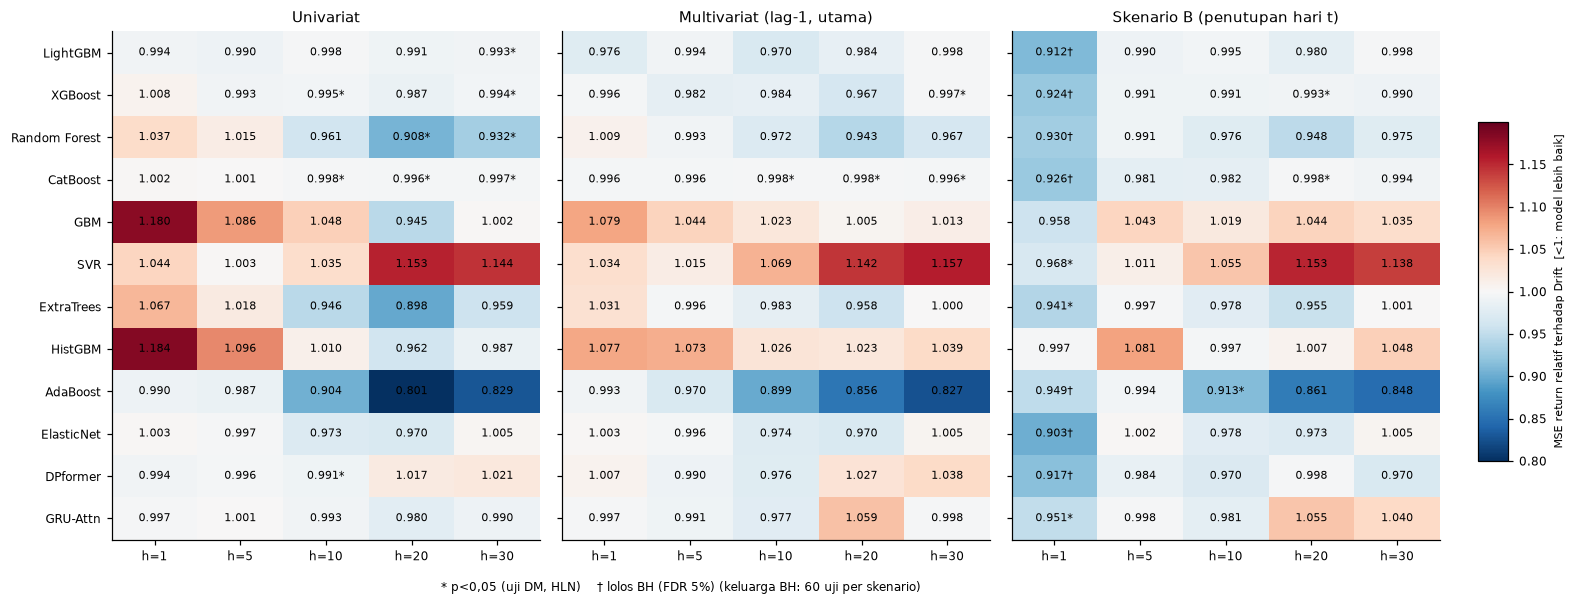

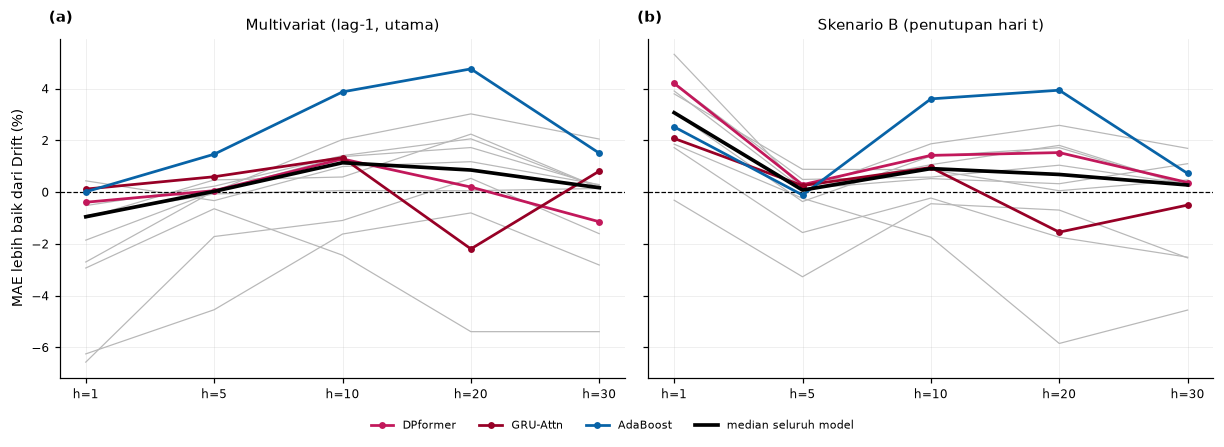

Rata-rata perbaikan MAE terhadap Drift (%), per skenario dan horizon (median model):


horizon,1,5,10,20,30
setup,,,,,
multivariat,-0.95,0.03,1.13,0.85,0.17
skenario_b,3.07,0.08,0.91,0.68,0.27


In [5]:
res = allt.rename(columns={'rel_mse_ret': 'rel', 'q_bh_setup': 'q_bh'})
fig = P.fig_dm_heatmap(res, models_b, HORIZONS, setups=('univariat', 'multivariat', LB),
                       setup_titles={'univariat': 'Univariat', 'multivariat': 'Multivariat (lag-1, utama)',
                                     LB: 'Skenario B (penutupan hari t)'},
                       bh_note=f'keluarga BH: {len(models_b) * len(HORIZONS)} uji per skenario', lim=0.2)
simpan(fig, 'fig_skenario_b_dm')

drb = pd.read_csv(os.path.join(RES, 'drift_benchmark.csv')).set_index('horizon')['MAE']
main = pd.read_csv(os.path.join(RES, 'tabel_hasil_final.csv'))
main = main[(main.setup == 'multivariat') & main.model.isin(models_b)][['setup', 'model', 'horizon', 'MAE', 'pct_vs_drift']]
mb = R.read_runs(SB_RUNS, [LB], models_b, HORIZONS, data_hash=DATA_HASH)[['setup', 'model', 'horizon', 'MAE']]
mb['pct_vs_drift'] = 100 * (mb.horizon.map(drb) - mb.MAE) / mb.horizon.map(drb)
gab = pd.concat([main, mb], ignore_index=True)
gab.to_csv(os.path.join(RES, 'skenario_b_mae_vs_drift.csv'), index=False)
fig = P.fig_gain_vs_horizon(gab, HORIZONS, highlight=reps + [wakil['ml']], setups=('multivariat', LB),
                            setup_titles={'multivariat': 'Multivariat (lag-1, utama)', LB: 'Skenario B (penutupan hari t)'})
simpan(fig, 'fig_skenario_b_mae')
print('Rata-rata perbaikan MAE terhadap Drift (%), per skenario dan horizon (median model):')
display(gab.groupby(['setup', 'horizon']).pct_vs_drift.median().unstack('horizon').round(2))

**Cara membaca.**

- Bila skenario B menurunkan rasio MSE terhadap Drift dan terhadap multivariat lag-1 secara konsisten pada banyak model/horizon (terutama h kecil), maka **waktu informasi** — bukan kurangnya model — yang membatasi hasil utama: indikator pasar hari-t membawa informasi yang tidak ada pada lag-1.
- Jika perbaikan terkonsentrasi di horizon pendek, itu masuk akal: korelasi harian antar pasar meluruh seiring horizon.
- Skenario B **tidak** menggantikan hasil utama. Untuk mengklaimnya di naskah, tuliskan asumsi waktu publikasi harga Antam secara eksplisit dan, bila bisa, verifikasi dengan jam publikasi resmi.